# 03 — Non-parametric tests of equality of psychometric functions

**Python port of `analyze_equality_1.m` and `analyze_equality_2.m`.**

## Why this notebook exists

Notebook 02 fits a psychometric function to every cell, and notebook 04
compares the fitted *parameters*. That is a powerful approach, but it leans on the model
being right: if the difference-of-Gaussians form is wrong, so is everything
built on top of it.

This notebook does something more basic and model-free. It asks, directly of the
**counts**, whether two sets of responses could plausibly have come from the
same underlying psychometric function — with no curve fitted at all. Two
questions are asked:

1. **`analyze_equality_1`** — are conditions 0 and 2 equivalent? They used the
   same standard (26.4 cd/m²) and differed only in when they were run, so any
   difference is *drift* in the observer over the course of data collection.
2. **`analyze_equality_2`** — do the psychometric functions for test-first and
   test-second (or test-left and test-right) differ? This is a direct,
   assumption-free test for the presence of an order effect.

Because the test uses only the data, the one cell excluded from the fitting
analyses for insufficient degrees of freedom is **not** excluded here.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import orderfx as O

PROJECT_ROOT = os.path.abspath('..')
REFERENCE_DIR = os.path.join(os.path.abspath('.'), 'reference')
OUTPUT_DIR = os.path.join(os.path.abspath('.'), 'outputs')
FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

def _tally(name):
    p = os.path.join(OUTPUT_DIR, name)
    if not os.path.isfile(p):
        p = os.path.join(REFERENCE_DIR, name)
    return O.load_tally(p)

data = {1: _tally('seq_data.txt'),     # task 1 = sequential
        2: _tally('sim_data.txt')}     # task 2 = simultaneous

N_SUB = 21
# condition number in the tally files (1-4) -> the labels used in the paper (0-3)
COND_STANDARD = {1: 26.4, 2: 13.2, 3: 26.4, 4: 39.5}
for t, df in data.items():
    print(O.TASK_LABELS[t - 1], df.shape)

sequential (1176, 10)
simultaneous (1176, 10)


## Step 1 — The generalized Berry–Mielke test

The test comes from García-Pérez and Núñez-Antón (2018). The setup is:

* Each **test luminance** forms a **stratum** — a small contingency table.
* Within a stratum the table is 2 × 2: rows are the two populations being
  compared, columns are the two responses (*same*, *different*).

$$\begin{array}{c|cc} & \text{same} & \text{different} \\\hline \text{population 1} & s_1 & d_1 \\ \text{population 2} & s_2 & d_2 \end{array}$$

* Seven test luminances therefore give seven strata, and the question is
  whether the two populations differ **anywhere across them**.

Why not just run a chi-square on each stratum and combine? Because with 24
trials per cell the chi-square approximation is poor. The Berry–Mielke approach
instead:

1. computes Pearson's statistic adjusted as $T = X^2\,(N-1)/N$;
2. derives the **exact** first three moments (mean, variance, skewness) of the
   permutation distribution of $T$ under the null — this is the long block of
   algebra in `PF_test`, and it is exact rather than asymptotic;
3. standardises $T$ and matches a **gamma** distribution to that skewness, so
   each stratum becomes a gamma variate;
4. sums the gamma variates across strata, which is again gamma-distributed, and
   reads off a single omnibus $p$-value.

Two kinds of stratum get dropped: those admitting only one permutation (they
carry no information), and those whose skewness falls below 0.5 (the gamma
approximation is unreliable there). Both rules are in the MATLAB code and both
are preserved in `orderfx.berry_mielke`.

In [2]:
# A quick check on the helper: with a single stratum the Mantel-Haenszel
# statistic must equal Pearson's chi-square adjusted by (N-1)/N.
from scipy.stats import chi2_contingency

demo = np.array([[12., 12.], [20., 4.]])
chi2_val = chi2_contingency(demo, correction=False)[0]
N = demo.sum()
print('Q_GMH from orderfx :', O.mantel_haenszel([demo])['Q_GMH'])
print('X^2 * (N-1)/N      :', chi2_val * (N - 1) / N)

# And what one Berry-Mielke test looks like in full.
sub, task, order = 1, 1, 1
u = data[task]
a = u[(u.sub_num == sub) & (u['cond'] == 1) & (u.test_pos == order)].sort_values('test')
b = u[(u.sub_num == sub) & (u['cond'] == 3) & (u.test_pos == order)].sort_values('test')
strata = O.build_strata(a['same'], a['diff'], b['same'], b['diff'])

print('\nstrata (rows = condition 0, condition 2; columns = same, different):')
for lev, s in zip(a['test'], strata):
    print(f'  {lev:6.2f} cd/m2  {s[0].astype(int)}  {s[1].astype(int)}')

res = O.berry_mielke(strata)
print(f"\nomnibus G = {res['omnibusG']:.4f}, c = {res['c_parameter']:.4f}, "
      f"p = {res['p_value']:.4f}")
print('strata dropped:', res['ExcludedTables'] or 'none')

Q_GMH from orderfx : 5.875
X^2 * (N-1)/N      : 5.875

strata (rows = condition 0, condition 2; columns = same, different):
   17.60 cd/m2  [ 3 21]  [10 14]
   19.80 cd/m2  [11 13]  [13 11]
   22.40 cd/m2  [17  7]  [22  2]
   26.40 cd/m2  [21  3]  [23  1]
   30.30 cd/m2  [17  7]  [18  6]
   34.70 cd/m2  [10 14]  [14 10]
   39.96 cd/m2  [ 5 19]  [ 6 18]

omnibus G = 7.2605, c = 4.7627, p = 0.1277
strata dropped: none


## Step 2 — `analyze_equality_1`: are conditions 0 and 2 the same?

Conditions 0 and 2 both used a standard of 26.4 cd/m². Condition 0 always ran
first, condition 2 later, so if the observer's performance were stable the two
should be statistically indistinguishable. One test is run per
observer × presentation mode × test position:

$$21 \times 2 \times 2 = 84 \text{ tests.}$$

Under true stability we would expect about 4 rejections (5%) at $\alpha$ = .05.

In [3]:
rows = []
for sub in range(1, N_SUB + 1):
    for task in (1, 2):
        for order in (1, 2):
            u = data[task]
            a = u[(u.sub_num == sub) & (u['cond'] == 1) & (u.test_pos == order)].sort_values('test')
            b = u[(u.sub_num == sub) & (u['cond'] == 3) & (u.test_pos == order)].sort_values('test')
            r = O.berry_mielke(O.build_strata(a['same'], a['diff'], b['same'], b['diff']))
            rows.append({
                'sub': sub, 'task': O.TASK_LABELS[task - 1],
                'position': O.ORDER_LABELS[task - 1][order - 1],
                'n_strata': len(a),
                'G': r['omnibusG'], 'c': r['c_parameter'], 'p': r['p_value'],
                'significant': (r['p_value'] is not None and r['p_value'] < 0.05),
                'n_dropped': len(r['ExcludedTables']),
            })

eq1 = pd.DataFrame(rows)
n_sig = int(eq1.significant.sum())
print(f'{n_sig} of {len(eq1)} tests significant  ({100 * n_sig / len(eq1):.1f}%)')
print(f'expected under stability: about {0.05 * len(eq1):.0f} (5%)')
print()
print(eq1.groupby(['task', 'position']).significant.sum().to_string())
eq1.head()

31 of 84 tests significant  (36.9%)
expected under stability: about 4 (5%)

task          position
sequential    1st          6
              2nd          5
simultaneous  left        11
              right        9


,sub,task,position,n_strata,G,c,p,significant,n_dropped
0,1,sequential,1st,7,7.260459,4.762697,0.127690,False,0
1,1,sequential,2nd,7,7.598764,3.711401,0.041847,True,1
2,1,simultaneous,left,7,12.692331,4.258608,0.001892,True,2
3,1,simultaneous,right,7,5.992901,5.366871,0.343277,False,1
4,2,sequential,1st,7,5.182029,4.829917,0.379058,False,0


So performance was **not** stable across the course of data collection:
rejections run far above the 5% that chance alone would produce. This is the
result the manuscript uses to argue against pooling conditions 0 and 2.

Note this says nothing about order effects — it compares the *same* test
position across two blocks run at different times.

## Step 3 — `analyze_equality_2`: do the two presentation orders differ?

This is the question the paper is actually about. For each observer, mode and
condition, the test-first data are compared against the test-second data
(or test-left against test-right):

$$21 \times 2 \times 4 = 168 \text{ tests.}$$

A rejection means the two psychometric functions differ *somehow* — the test
does not say whether the difference is Type A, Type B, or both, nor in which
direction. That is the price of not assuming a model.

In [4]:
rows = []
binary = np.zeros((N_SUB, 2, 4), dtype=int)
for si, sub in enumerate(range(1, N_SUB + 1)):
    for ti, task in enumerate((1, 2)):
        for ci, cond in enumerate((1, 2, 3, 4)):
            u = data[task]
            a = u[(u.sub_num == sub) & (u['cond'] == cond) & (u.test_pos == 1)].sort_values('test')
            b = u[(u.sub_num == sub) & (u['cond'] == cond) & (u.test_pos == 2)].sort_values('test')
            r = O.berry_mielke(O.build_strata(a['same'], a['diff'], b['same'], b['diff']))
            sig = (r['p_value'] is not None and r['p_value'] < 0.05)
            binary[si, ti, ci] = int(sig)
            rows.append({
                'sub': sub, 'task': O.TASK_LABELS[task - 1],
                'condition': cond - 1, 'standard': COND_STANDARD[cond],
                'G': r['omnibusG'], 'c': r['c_parameter'], 'p': r['p_value'],
                'significant': sig,
            })

eq2 = pd.DataFrame(rows)
tot = int(eq2.significant.sum())
seq = int(binary[:, 0, :].sum())
sim = int(binary[:, 1, :].sum())
print(f'total        : {tot} of 168 significant ({100 * tot / 168:.2f}%)')
print(f'sequential   : {seq} of  84 ({100 * seq / 84:.2f}%)')
print(f'simultaneous : {sim} of  84 ({100 * sim / 84:.2f}%)')
print()
print(eq2.pivot_table(index='condition', columns='task',
                      values='significant', aggfunc='sum').to_string())

total        : 81 of 168 significant (48.21%)
sequential   : 49 of  84 (58.33%)
simultaneous : 32 of  84 (38.10%)

task       sequential  simultaneous
condition                          
0                  16             6
1                   9            11
2                  12             7
3                  12             8


### Comparing the two modes with a paired test

Every observer contributes to both modes, so the two rejection rates are
**paired**, not independent. The closing block of `analyze_equality_2.m`
therefore uses a McNemar-style z test on the discordant pairs,

$$z = \frac{f-g}{\sqrt{f+g}},$$

where $f$ counts cases significant in sequential but not simultaneous and $g$
the reverse, together with the Newcombe (1998b) confidence interval for the
difference between paired proportions. That interval combines Wilson score
bounds for each marginal proportion with an estimate $\hat\varphi$ of the
association between them, which is why it is asymmetric about the difference.

In [5]:
x = binary[:, 0, :].reshape(-1, order='F')   # sequential
y = binary[:, 1, :].reshape(-1, order='F')   # simultaneous
pp = O.paired_proportions(x, y)

print('2 x 2 table of paired outcomes (rows = sequential, cols = simultaneous):')
print(pd.DataFrame([[pp['e'], pp['f']], [pp['g'], pp['h']]],
                   index=['sig', 'not sig'], columns=['sig', 'not sig']).to_string())
print()
print(f"sequential rejection rate   : {pp['p1']:.4f}")
print(f"simultaneous rejection rate : {pp['p2']:.4f}")
print(f"difference                  : {pp['difference']:.4f}")
print(f"z = {pp['z']:.3f}, p = {pp['p_value']:.3f}, "
      f"95% CI [{pp['CI'][0]:.3f}, {pp['CI'][1]:.3f}]")

2 x 2 table of paired outcomes (rows = sequential, cols = simultaneous):
         sig  not sig
sig       22       27
not sig   10       25

sequential rejection rate   : 0.5833
simultaneous rejection rate : 0.3810
difference                  : 0.2024
z = 2.795, p = 0.005, 95% CI [0.062, 0.331]


Order effects are detected considerably more often with sequential than with
simultaneous presentations, and the difference is significant. This is the
model-free counterpart of the Type B result in notebook 04 — and it is reassuring
that two quite different routes to the question agree.

## Step 4 — Figures

For each observer the MATLAB scripts draw a grid of raw proportion-same curves,
one row per population being compared. Rather than reproduce the interactive
tabbed figure, we save one page per observer to a PDF, and show a summary
figure of rejection rates.

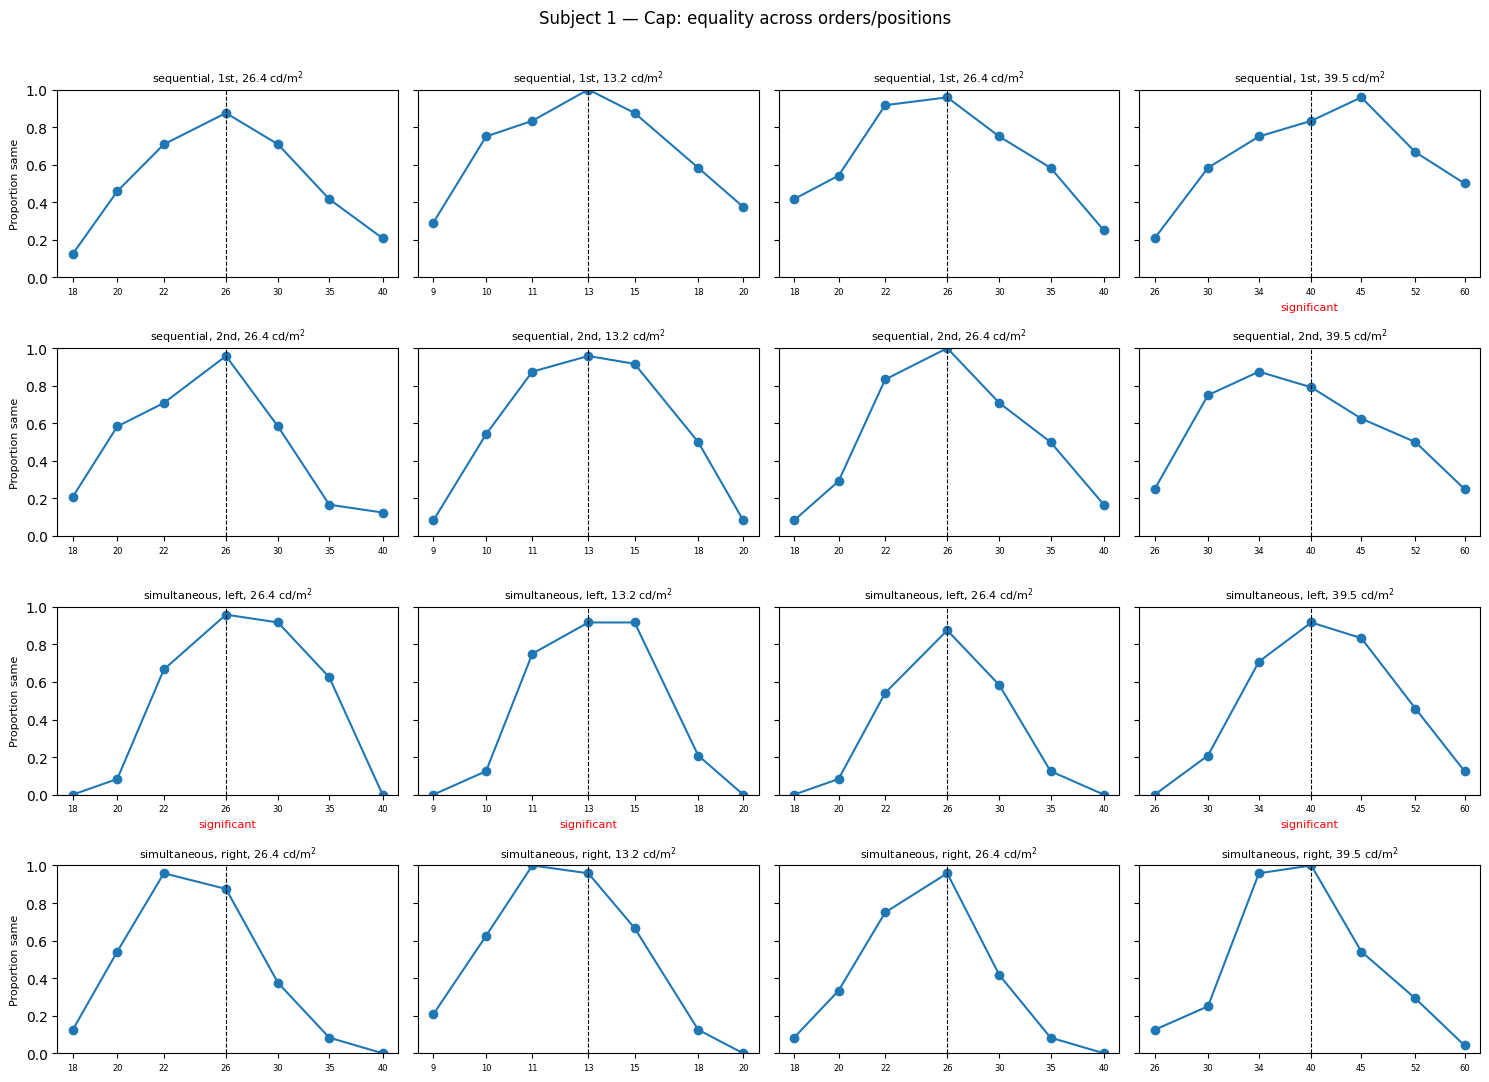

In [6]:
def plot_equality_subject(sub):
    fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharey=True)
    for ti, task in enumerate((1, 2)):
        for ci, cond in enumerate((1, 2, 3, 4)):
            u = data[task]
            a = u[(u.sub_num == sub) & (u['cond'] == cond) & (u.test_pos == 1)].sort_values('test')
            b = u[(u.sub_num == sub) & (u['cond'] == cond) & (u.test_pos == 2)].sort_values('test')
            ax = axes[ti * 2, ci]
            ax2 = axes[ti * 2 + 1, ci]
            lab = O.ORDER_LABELS[task - 1]
            for axis, d, name in [(ax, a, lab[0]), (ax2, b, lab[1])]:
                axis.plot(np.log(d['test']), d['same'] / d['total'], 'o-')
                axis.axvline(np.log(COND_STANDARD[cond]), color='k', ls='--', lw=0.8)
                axis.set_ylim(0, 1)
                axis.set_xticks(np.log(d['test']))
                axis.set_xticklabels([f'{v:.0f}' for v in d['test']], fontsize=6)
                axis.set_title(f'{O.TASK_LABELS[task-1]}, {name}, '
                               f'{COND_STANDARD[cond]} cd/m$^2$', fontsize=8)
            row = eq2[(eq2['sub'] == sub) & (eq2.task == O.TASK_LABELS[task - 1])
                      & (eq2.condition == cond - 1)].iloc[0]
            if row.significant:
                ax.set_xlabel('significant', color='r', fontsize=8)
            axes[ti * 2, 0].set_ylabel('Proportion same', fontsize=8)
            axes[ti * 2 + 1, 0].set_ylabel('Proportion same', fontsize=8)
    fig.suptitle(f'Subject {sub} — {O.NAMES[sub-1]}: equality across orders/positions')
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    return fig

fig = plot_equality_subject(1)
plt.show()

In [7]:
from matplotlib.backends.backend_pdf import PdfPages

pdf_path = os.path.join(FIG_DIR, 'equality_across_orders.pdf')
with PdfPages(pdf_path) as pdf:
    for sub in range(1, N_SUB + 1):
        f = plot_equality_subject(sub)
        pdf.savefig(f)
        plt.close(f)
print('wrote', pdf_path)

wrote /sessions/jolly-sweet-hypatia/mnt/Order-effect/order-effect/analysis/outputs/figures/equality_across_orders.pdf


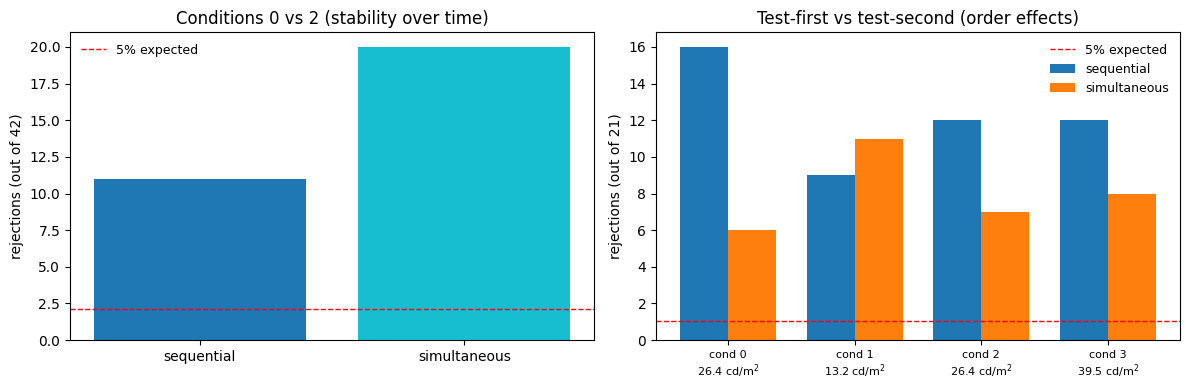

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
counts = eq1.groupby('task').significant.sum()
ax.bar(counts.index, counts.values, color=['tab:blue', 'tab:cyan'])
ax.axhline(0.05 * 42, color='r', ls='--', lw=1, label='5% expected')
ax.set_ylabel('rejections (out of 42)')
ax.set_title('Conditions 0 vs 2 (stability over time)')
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
piv = eq2.pivot_table(index='condition', columns='task',
                      values='significant', aggfunc='sum')
w = 0.38
idx = np.arange(len(piv))
for i, c in enumerate(piv.columns):
    ax.bar(idx + (i - 0.5) * w, piv[c], w, label=c)
ax.axhline(0.05 * 21, color='r', ls='--', lw=1, label='5% expected')
ax.set_xticks(idx)
ax.set_xticklabels([f'cond {c}\n{COND_STANDARD[c+1]} cd/m$^2$' for c in piv.index],
                   fontsize=8)
ax.set_ylabel('rejections (out of 21)')
ax.set_title('Test-first vs test-second (order effects)')
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'figure4_equality_tests.png'), dpi=150)
plt.show()

In [9]:
eq1.to_csv(os.path.join(OUTPUT_DIR, 'equality_conditions_0_vs_2.csv'), index=False)
eq2.to_csv(os.path.join(OUTPUT_DIR, 'equality_across_orders.csv'), index=False)
print('wrote equality_conditions_0_vs_2.csv and equality_across_orders.csv')

wrote equality_conditions_0_vs_2.csv and equality_across_orders.csv


## Step 5 — Verification against the manuscript

The Results section of the manuscript reports specific numbers for both
analyses. Because this test is exact and involves no optimiser, agreement
should be exact too — which makes it a stringent check on the port.

In [10]:
checks = [
    ('conditions 0 vs 2: rejections (of 84)', n_sig, 31),
    ('conditions 0 vs 2: percentage', round(100 * n_sig / 84, 2), 36.90),
    ('orders: total rejections (of 168)', tot, 81),
    ('orders: sequential (of 84)', seq, 49),
    ('orders: simultaneous (of 84)', sim, 32),
    ('paired z', round(pp['z'], 3), 2.795),
    ('paired p', round(pp['p_value'], 3), 0.005),
    ('CI lower', round(pp['CI'][0], 3), 0.062),
    ('CI upper', round(pp['CI'][1], 3), 0.331),
]
report = pd.DataFrame(checks, columns=['quantity', 'python', 'manuscript'])
report['match'] = np.isclose(report.python.astype(float),
                             report.manuscript.astype(float), atol=0.011)
display(report)
print('\nall match:', bool(report.match.all()))

,quantity,python,manuscript,match
0,conditions 0 vs 2: rejections (of 84),31.000,31.000,True
1,conditions 0 vs 2: percentage,36.900,36.900,True
2,orders: total rejections (of 168),81.000,81.000,True
3,orders: sequential (of 84),49.000,49.000,True
4,orders: simultaneous (of 84),32.000,32.000,True
5,paired z,2.795,2.795,True
6,paired p,0.005,0.005,True
7,CI lower,0.062,0.062,True
8,CI upper,0.331,0.331,True



all match: True


### A discrepancy worth noting

The manuscript states that 81 of the 168 order tests were significant and calls
this **43.55%**. But 81/168 = **48.21%**, and the two component figures it gives
(49 and 32, both of which reproduce exactly) do sum to 81. The percentage looks
like a typographical slip; the counts are right.

---

## Summary

* A model-free test of whether two sets of same/different counts could come
  from the same psychometric function, using the exact permutation moments of
  an adjusted Pearson statistic combined across stimulus levels.
* Conditions 0 and 2 differ far more often than chance allows, so performance
  drifted across data collection.
* Test-first and test-second functions differ in 49 of 84 sequential cases but
  only 32 of 84 simultaneous cases, a significant paired difference.
* Every number reproduces the manuscript exactly.